# Home Credit Default Risk - EDA and Cleaning

## 1. Data Loading & Merging

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

target = "PaymentDifficultyFlag"

In [2]:
# load the fact table and the 6 dimension tables
fact = pd.read_csv("LoanApplication.csv")
customer = pd.read_csv("Customer.csv", encoding="utf-8-sig")
employment = pd.read_csv("Employment.csv", encoding="utf-8-sig")
household = pd.read_csv("HouseHold.csv", encoding="utf-8-sig")
loan_profile = pd.read_csv("LoanProfile.csv", encoding="utf-8-sig")
organization = pd.read_csv("Organization.csv", encoding="utf-8-sig")

# the risk file may be saved with & or _ in the name
risk_file = "Risk&History.csv" if os.path.exists("Risk&History.csv") else "Risk_History.csv"
risk = pd.read_csv(risk_file, encoding="utf-8-sig")

print("Fact table:", fact.shape)

Fact table: (307511, 50)


In [3]:
# each key must be unique in its dimension table
dims = {"CustomerKey": customer, "EmploymentKey": employment, "HouseholdKey": household,
        "LoanProfileKey": loan_profile, "OrganizationKey": organization, "RiskHistoryKey": risk}

for key, dim in dims.items():
    unmatched = (~fact[key].isin(dim[key])).sum()
    print(key, "| unique:", dim[key].is_unique, "| fact keys with no match:", unmatched)

CustomerKey | unique: True | fact keys with no match: 0
EmploymentKey | unique: True | fact keys with no match: 0
HouseholdKey | unique: True | fact keys with no match: 0
LoanProfileKey | unique: True | fact keys with no match: 0
OrganizationKey | unique: True | fact keys with no match: 0
RiskHistoryKey | unique: True | fact keys with no match: 0


In [4]:
# left join every dimension onto the fact table
df = fact.copy()
for key, dim in dims.items():
    df = df.merge(dim, on=key, how="left")

print("Rows before:", len(fact), "| rows after:", len(df))
assert len(df) == len(fact)   # the joins must not add rows
df.head()

Rows before: 307511 | rows after: 307511


,ApplicationID,CustomerKey,HouseholdKey,EmploymentKey,OrganizationKey,LoanProfileKey,RiskHistoryKey,PaymentDifficultyFlag,IncomeAmount,IncomeAmountCapped,...,BureauOverdueGroup,BureauOverdueSort,PreviousRefusalGroup,PreviousRefusalSort,InstallmentLateGroup,InstallmentLateSort,InstallmentSevereLateGroup,InstallmentSevereLateSort,InstallmentUnderpaidGroup,InstallmentUnderpaidSort
0,100002,480,17,266,6,34,253,1,202500.0,202500.0,...,No overdue credit,1,Never refused,1,Never late,1,Never 30+ days late,1,Always paid in full,1
1,100003,237,13,148,41,77,151,0,270000.0,270000.0,...,No overdue credit,1,Never refused,1,Never late,1,Never 30+ days late,1,Always paid in full,1
2,100004,628,23,270,12,195,57,0,67500.0,67500.0,...,No overdue credit,1,Never refused,1,Never late,1,Never 30+ days late,1,Always paid in full,1
3,100006,224,17,269,6,3,339,0,135000.0,135000.0,...,No bureau record,0,Some refusals,2,Never late,1,Never 30+ days late,1,Always paid in full,1
4,100007,628,17,244,39,110,47,0,121500.0,121500.0,...,No overdue credit,1,Never refused,1,Late in 10-30%,3,Never 30+ days late,1,Always paid in full,1


## 2. Data Cleaning & Profiling

In [5]:
print(df.shape)
df.info()

(307511, 88)
<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Data columns (total 88 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   ApplicationID                  307511 non-null  int64  
 1   CustomerKey                    307511 non-null  int64  
 2   HouseholdKey                   307511 non-null  int64  
 3   EmploymentKey                  307511 non-null  int64  
 4   OrganizationKey                307511 non-null  int64  
 5   LoanProfileKey                 307511 non-null  int64  
 6   RiskHistoryKey                 307511 non-null  int64  
 7   PaymentDifficultyFlag          307511 non-null  int64  
 8   IncomeAmount                   307511 non-null  float64
 9   IncomeAmountCapped             307511 non-null  float64
 10  LoanAmount                     307511 non-null  float64
 11  AnnuityAmount                  307499 non-null  float64
 12  GoodsPriceAmount            

In [6]:
# missing values (only columns that have some)
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
print(missing_pct)

OwnCarAge                        65.99
ExtSource1                       56.38
ExtSource3                       19.83
YearsEmployed                    18.01
BureauDebtToCreditRatio          17.03
BureauTotalDebt                  16.71
BureauTotalCredit                14.32
BureauMaxDaysOverdue             14.31
BureauEnquiriesLastYear          13.50
PreviousRefusalRate               5.35
PreviousDaysSinceLastDecision     5.35
InstallmentLateRate               5.16
InstallmentMaxDaysLate            5.16
InstallmentAvgDaysLate            5.16
SocialCircleDefaults60            0.33
SocialCircleDefaults30            0.33
ExtSource2                        0.21
GoodsPriceAmount                  0.09
EstimatedLoanTermMonths           0.00
AnnuityToIncomeRatio              0.00
AnnuityAmount                     0.00
FamilyMemberCount                 0.00
dtype: float64


In [7]:
# duplicate applications
print("Duplicate ApplicationID:", df["ApplicationID"].duplicated().sum())
print("Duplicate rows:", df.duplicated().sum())

Duplicate ApplicationID: 0
Duplicate rows: 0


In [8]:
# how many applications point to the -1 (Unassigned) row in each dimension
for key in dims:
    n = (df[key] == -1).sum()
    print(key, n, f"({n / len(df) * 100:.2f}%)")

CustomerKey 0 (0.00%)
EmploymentKey 0 (0.00%)
HouseholdKey 0 (0.00%)
LoanProfileKey 0 (0.00%)
OrganizationKey 0 (0.00%)
RiskHistoryKey 0 (0.00%)


In [9]:
# data quality flags
print(df["IncomeOutlierFlag"].value_counts())
print(df["BureauDebtExceedsCreditFlag"].value_counts())

# default rate for each flag
print(df.groupby("IncomeOutlierFlag")[target].mean() * 100)
print(df.groupby("BureauDebtExceedsCreditFlag")[target].mean() * 100)

IncomeOutlierFlag
0    307261
1       250
Name: count, dtype: int64
BureauDebtExceedsCreditFlag
0    305925
1      1586
Name: count, dtype: int64
IncomeOutlierFlag
0    8.075219
1    5.200000
Name: PaymentDifficultyFlag, dtype: float64
BureauDebtExceedsCreditFlag
0     8.018305
1    18.600252
Name: PaymentDifficultyFlag, dtype: float64


       IncomeAmount  IncomeAmountCapped
count  3.075110e+05       307511.000000
mean   1.687979e+05       167857.961613
std    2.371231e+05        92662.046923
min    2.565000e+04        25650.000000
25%    1.125000e+05       112500.000000
50%    1.471500e+05       147150.000000
75%    2.025000e+05       202500.000000
max    1.170000e+08      1000000.000000
Rows changed by capping: 250


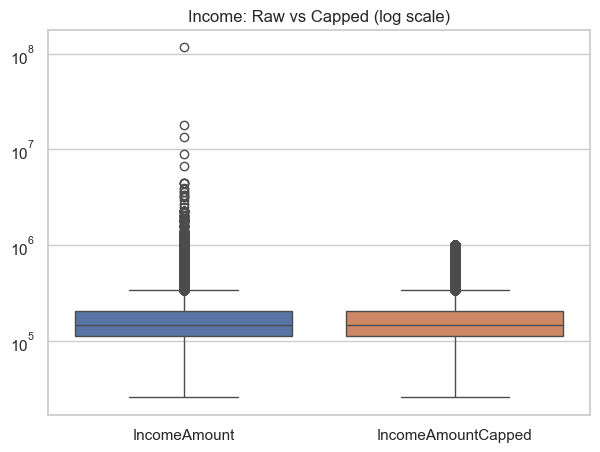

In [10]:
# income: raw vs capped
print(df[["IncomeAmount", "IncomeAmountCapped"]].describe())
print("Rows changed by capping:", (df["IncomeAmount"] != df["IncomeAmountCapped"]).sum())

plt.figure(figsize=(7, 5))
sns.boxplot(data=df[["IncomeAmount", "IncomeAmountCapped"]])
plt.yscale("log")
plt.title("Income: Raw vs Capped (log scale)")
plt.savefig("outputs/income_raw_vs_capped.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
# ratio distributions before clipping
ratios = ["CreditToIncomeRatio", "AnnuityToIncomeRatio"]
print(df[ratios].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99, 0.995]))

       CreditToIncomeRatio  AnnuityToIncomeRatio
count        307511.000000         307499.000000
mean              3.957672              0.180933
std               2.689693              0.094575
min               0.000000              0.000200
25%               2.020000              0.114800
50%               3.270000              0.162800
75%               5.160000              0.229100
95%               9.160000              0.354700
99%              13.030000              0.483504
99.5%            14.804500              0.550600
max              84.740000              1.876000


In [12]:
# clip both ratios at the 99.5th percentile (keep the original columns)
for col in ratios:
    df[col + "_clip"] = df[col].clip(upper=df[col].quantile(0.995))

print(df[["CreditToIncomeRatio_clip", "AnnuityToIncomeRatio_clip"]].describe())

       CreditToIncomeRatio_clip  AnnuityToIncomeRatio_clip
count             307511.000000              307499.000000
mean                   3.942796                   0.180380
std                    2.606469                   0.091627
min                    0.000000                   0.000200
25%                    2.020000                   0.114800
50%                    3.270000                   0.162800
75%                    5.160000                   0.229100
max                   14.804500                   0.550600


Cleaning decisions:
- No rows are dropped, the table is already one row per application.
- `IncomeAmountCapped` is used instead of `IncomeAmount`.
- The two ratios are clipped at P99.5 because of a few extreme values.
- Missing `ExtSource` and `OwnCarAge` values are left as they are (no imputation).
- `Unassigned` and `Unknown` stay as their own categories.

## 3. Overall Default Rate

Overall default rate: 8.07%
PaymentDifficultyFlag
0    282686
1     24825
Name: count, dtype: int64


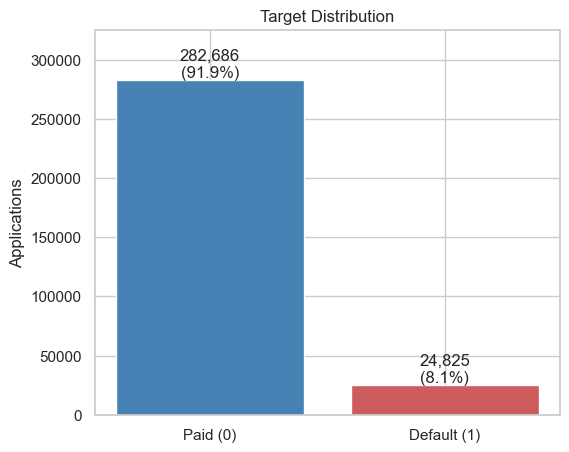

In [13]:
baseline = df[target].mean() * 100
print(f"Overall default rate: {baseline:.2f}%")
print(df[target].value_counts())

counts = df[target].value_counts().sort_index()
plt.figure(figsize=(6, 5))
plt.bar(["Paid (0)", "Default (1)"], counts.values, color=["steelblue", "indianred"])
for i, v in enumerate(counts.values):
    plt.text(i, v, f"{v:,}\n({v / len(df) * 100:.1f}%)", ha="center", va="bottom")
plt.ylim(0, counts.max() * 1.15)
plt.title("Target Distribution")
plt.ylabel("Applications")
plt.savefig("outputs/target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Default Rate by Segment

In [14]:
def plot_default_rate(col, ax, sort_col=None):
    rate = df.groupby(col)[target].mean() * 100
    size = df.groupby(col)[target].size()
    rate = rate[size >= 100]   # skip very small groups

    # order bars with the sort column if there is one, otherwise highest rate first
    if sort_col:
        order = df.groupby(col)[sort_col].min().sort_values().index
        rate = rate.reindex([x for x in order if x in rate.index])
    else:
        rate = rate.sort_values(ascending=False)

    colors = ["indianred" if r > baseline else "steelblue" for r in rate.values]
    labels = rate.index.astype(str)

    ax.bar(labels, rate.values, color=colors)
    ax.axhline(baseline, color="black", linestyle="--", label=f"Overall: {baseline:.2f}%")
    for i, r in enumerate(rate.values):
        ax.text(i, r + 0.2, f"{r:.1f}%", ha="center")
    ax.set_ylim(0, rate.max() * 1.2)
    ax.set_title("Default Rate by " + col)
    ax.set_ylabel("Default rate (%)")
    ax.tick_params(axis="x", rotation=30)
    plt.setp(ax.get_xticklabels(), ha="right")
    ax.legend()

### Customer

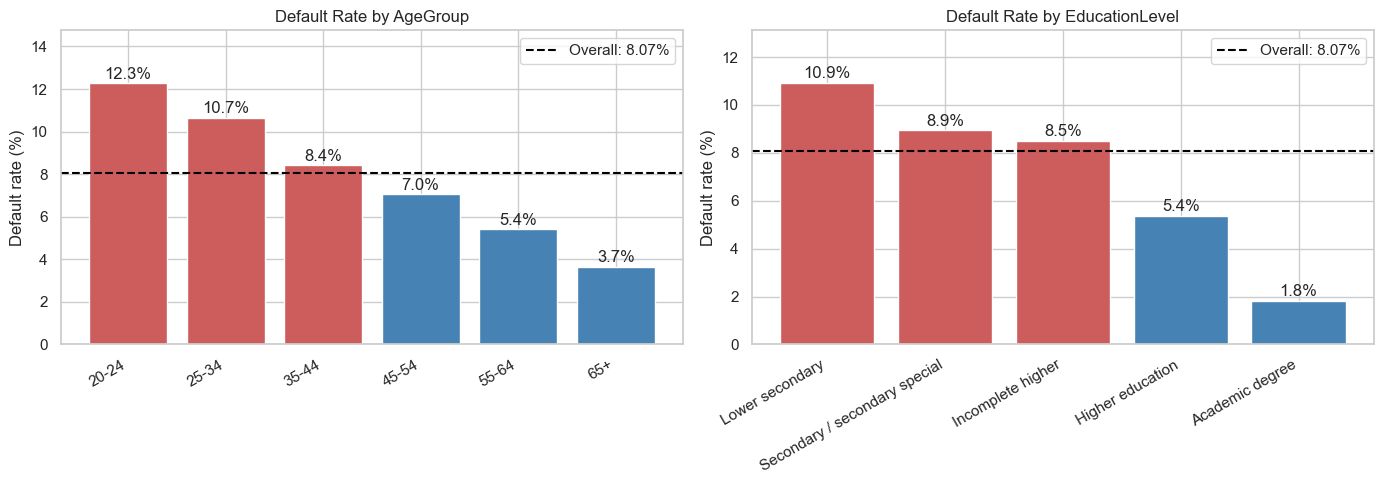

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_default_rate("AgeGroup", axes[0], "AgeGroupSort")
plot_default_rate("EducationLevel", axes[1], "EducationSort")
plt.tight_layout()
plt.savefig("outputs/customer_default_rate.png", dpi=300, bbox_inches="tight")
plt.show()

### Employment

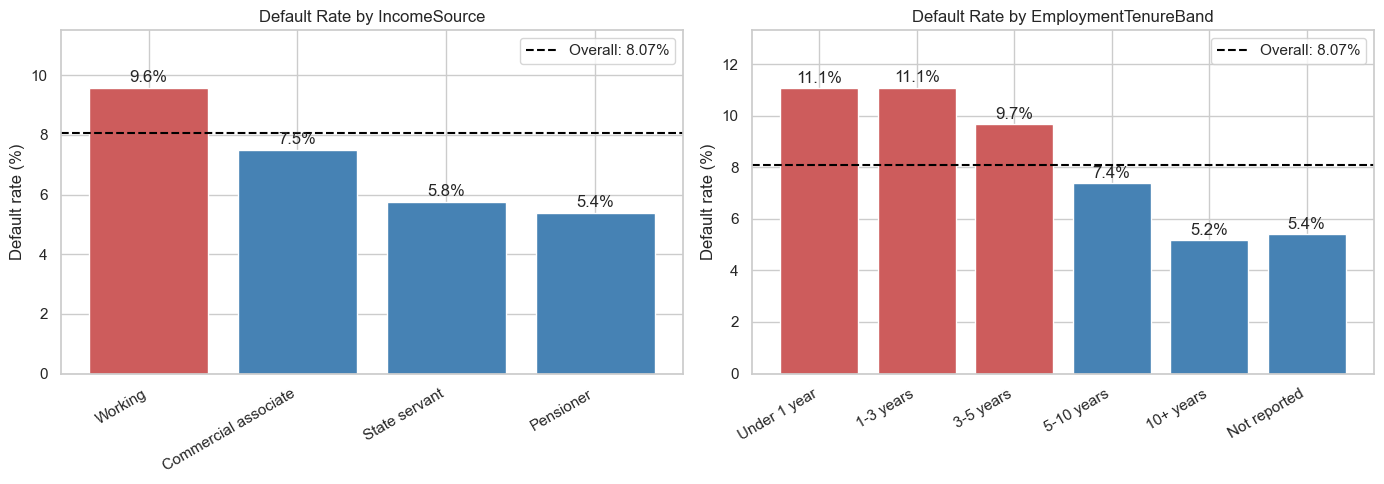

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_default_rate("IncomeSource", axes[0])
plot_default_rate("EmploymentTenureBand", axes[1], "EmploymentTenureSort")
plt.tight_layout()
plt.savefig("outputs/employment_default_rate.png", dpi=300, bbox_inches="tight")
plt.show()

### Household

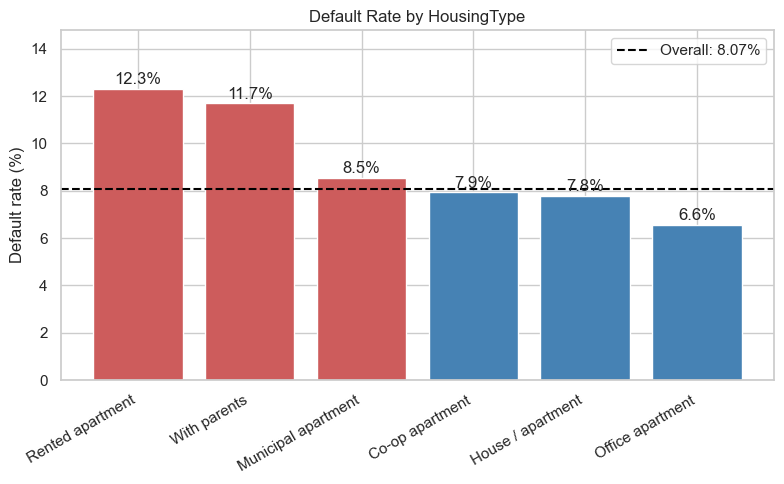

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_default_rate("HousingType", ax)
plt.tight_layout()
plt.savefig("outputs/housing_default_rate.png", dpi=300, bbox_inches="tight")
plt.show()

### Loan Profile

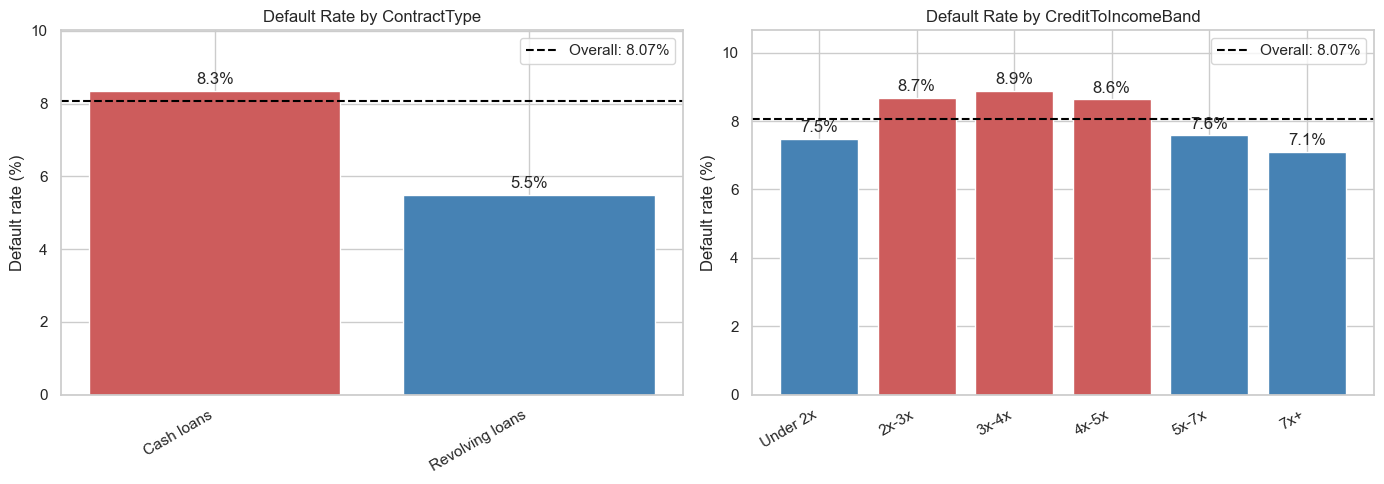

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_default_rate("ContractType", axes[0])
plot_default_rate("CreditToIncomeBand", axes[1], "CreditToIncomeSort")
plt.tight_layout()
plt.savefig("outputs/loan_profile_default_rate.png", dpi=300, bbox_inches="tight")
plt.show()

### Risk History

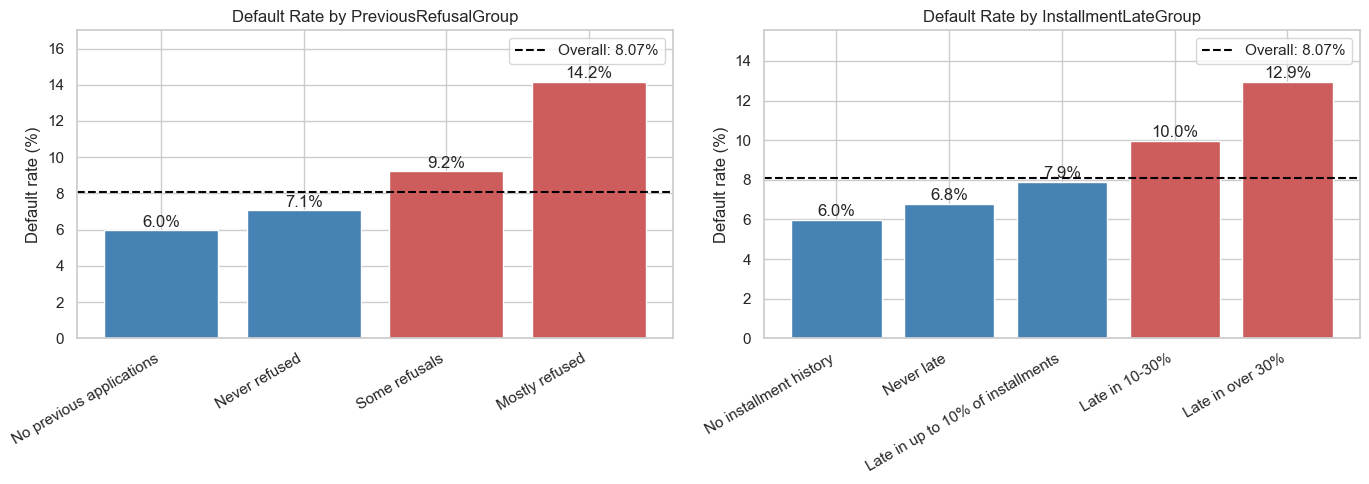

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_default_rate("PreviousRefusalGroup", axes[0], "PreviousRefusalSort")
plot_default_rate("InstallmentLateGroup", axes[1], "InstallmentLateSort")
plt.tight_layout()
plt.savefig("outputs/risk_history_default_rate.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. External Score & Correlation

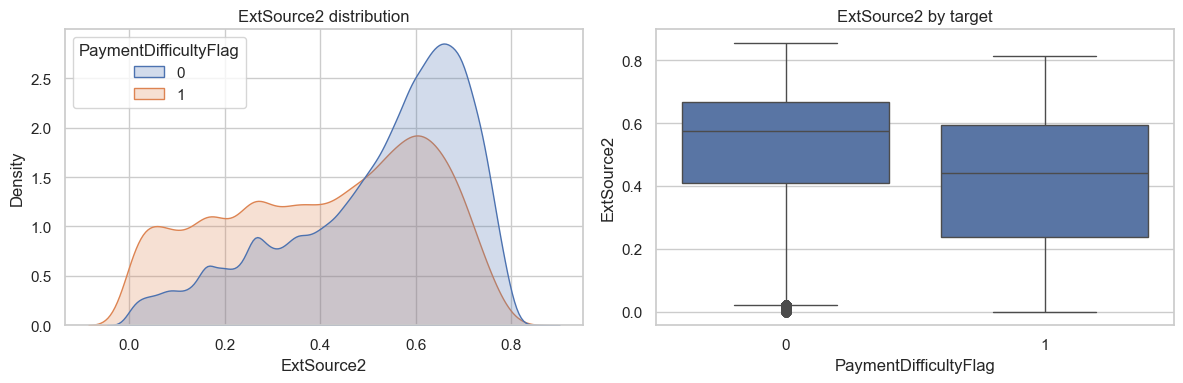

In [20]:
# ExtSource2 distribution and boxplot by target
data = df[["ExtSource2", target]].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=data, x="ExtSource2", hue=target, common_norm=False, fill=True, ax=axes[0])
sns.boxplot(data=data, x=target, y="ExtSource2", ax=axes[1])
axes[0].set_title("ExtSource2 distribution")
axes[1].set_title("ExtSource2 by target")
plt.tight_layout()
plt.savefig("outputs/ExtSource2_by_target.png", dpi=300, bbox_inches="tight")
plt.show()

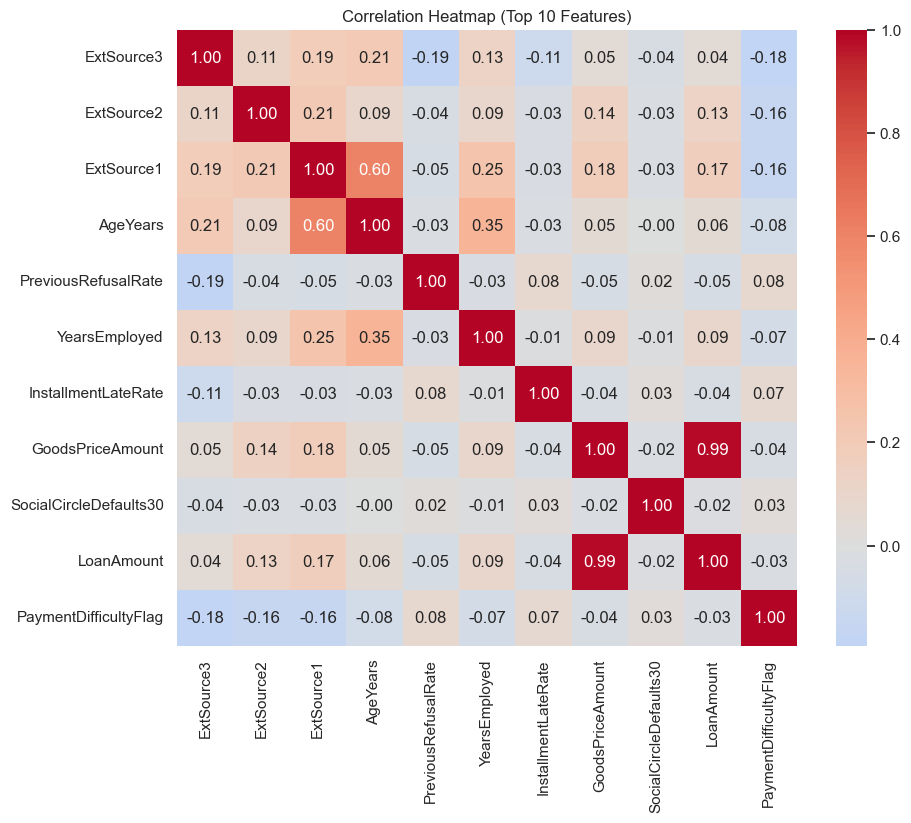

In [21]:
# keep the 10 numeric columns most correlated with the target
num_cols = ["ExtSource1", "ExtSource2", "ExtSource3", "AgeYears", "YearsEmployed",
            "IncomeAmountCapped", "LoanAmount", "AnnuityAmount", "GoodsPriceAmount",
            "CreditToIncomeRatio_clip", "AnnuityToIncomeRatio_clip",
            "BureauMaxDaysOverdue", "PreviousRefusalRate", "InstallmentLateRate",
            "BureauEnquiriesLastYear", "SocialCircleDefaults30"]

corr_with_target = df[num_cols].corrwith(df[target])
top10 = corr_with_target.abs().sort_values(ascending=False).head(10).index.tolist()
corr = df[top10 + [target]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Top 10 Features)")
plt.savefig("outputs/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Key Findings

In [22]:
print(f"Overall default rate: {baseline:.2f}% ({df[target].sum():,} of {len(df):,} applications)")

# highest and lowest default rate in each column (groups with at least 1000 applications)
cols = ["AgeGroup", "EducationLevel", "Gender", "IncomeSource", "EmploymentTenureBand",
        "OccupationType", "HousingType", "OwnsCar", "OwnsRealty", "RegionRating",
        "ContractType", "CreditToIncomeBand", "AnnuityToIncomeBand", "OrganizationSector",
        "BureauOverdueGroup", "PreviousRefusalGroup", "InstallmentLateGroup",
        "InstallmentSevereLateGroup"]

print("\nHighest and lowest risk group per column:")
for col in cols:
    g = df.groupby(col)[target].agg(["mean", "size"])
    g = g[g["size"] >= 1000]
    high, low = g["mean"].idxmax(), g["mean"].idxmin()
    print(f"{col}: highest = {high} ({g.loc[high, 'mean'] * 100:.1f}%), lowest = {low} ({g.loc[low, 'mean'] * 100:.1f}%)")

Overall default rate: 8.07% (24,825 of 307,511 applications)

Highest and lowest risk group per column:
AgeGroup: highest = 20-24 (12.3%), lowest = 65+ (3.7%)
EducationLevel: highest = Lower secondary (10.9%), lowest = Higher education (5.4%)
Gender: highest = Male (10.1%), lowest = Female (7.0%)
IncomeSource: highest = Working (9.6%), lowest = Pensioner (5.4%)
EmploymentTenureBand: highest = 1-3 years (11.1%), lowest = 10+ years (5.2%)
OccupationType: highest = Low-skill Laborers (17.2%), lowest = Accountants (4.8%)
HousingType: highest = Rented apartment (12.3%), lowest = Office apartment (6.6%)
OwnsCar: highest = No (8.5%), lowest = Yes (7.2%)
OwnsRealty: highest = No (8.3%), lowest = Yes (8.0%)
RegionRating: highest = 3 (11.1%), lowest = 1 (4.8%)
ContractType: highest = Cash loans (8.3%), lowest = Revolving loans (5.5%)
CreditToIncomeBand: highest = 3x-4x (8.9%), lowest = 7x+ (7.1%)
AnnuityToIncomeBand: highest = 25%-35% (8.7%), lowest = Under 10% (7.3%)
OrganizationSector: highest

In [23]:
# external scores: average for paid vs default
print("Average external scores by target:")
print(df.groupby(target)[["ExtSource1", "ExtSource2", "ExtSource3"]].mean().round(3))

# default rate when the score is missing vs present
print("\nDefault rate (%) when the score is missing vs present:")
for col in ["ExtSource1", "ExtSource2", "ExtSource3"]:
    print(col, df.groupby(df[col].isnull())[target].mean().mul(100).round(2).to_dict())

# strongest correlations with the target
print("\nCorrelation with", target)
print(corr[target].drop(target).sort_values(key=abs, ascending=False).head(6).round(3))

Average external scores by target:
                       ExtSource1  ExtSource2  ExtSource3
PaymentDifficultyFlag                                    
0                           0.511       0.523       0.521
1                           0.387       0.411       0.391

Default rate (%) when the score is missing vs present:
ExtSource1 {False: 7.5, True: 8.52}
ExtSource2 {False: 8.07, True: 7.88}
ExtSource3 {False: 7.77, True: 9.31}

Correlation with PaymentDifficultyFlag
ExtSource3            -0.179
ExtSource2            -0.160
ExtSource1            -0.155
AgeYears              -0.078
PreviousRefusalRate    0.078
YearsEmployed         -0.075
Name: PaymentDifficultyFlag, dtype: float64
